# 03 Predictive modelling: CKD risk model (PB4)
Group 5 PROHI: Risk Factor Prediction of Chronic Kidney Disease

User: Health Informatician (clinical decision support).

Question: can a new patient be classified as having CKD from routine clinical and laboratory tests, and how reliable is the risk score?

The dataset has one visit per patient, so the model detects **current** CKD; it cannot predict future progression or kidney failure.

Low-resource angle: we compare a **full model** (all 25 routine tests) with a **cheap-test model** that uses only medical history, a urine dipstick, blood pressure and age (no blood tests).

Requires `data_prep.py` version 2 in the repo (with FEATURES_V2).

In [2]:
GITHUB_USER = "mhoyor"

%cd /content
!rm -rf ckd-risk-app
!git clone https://github.com/{GITHUB_USER}/ckd-risk-app.git
%cd /content/ckd-risk-app

/content
Cloning into 'ckd-risk-app'...
remote: Enumerating objects: 42, done.
remote: Counting objects: 100% (42/42), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 42 (delta 16), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (42/42), 450.96 KiB | 5.93 MiB/s, done.
Resolving deltas: 100% (16/16), done.
/content/ckd-risk-app


In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, cross_val_predict, learning_curve)
from sklearn.metrics import (make_scorer, recall_score, roc_auc_score, f1_score, accuracy_score,
                             confusion_matrix, roc_curve, brier_score_loss)
from sklearn.calibration import calibration_curve
from data_prep import load_data, FEATURES, FEATURES_V2
from viz import apply_style, MODEL_COLORS, MODEL_STYLES, MUTED, TEXT

apply_style()
os.makedirs("figures", exist_ok=True)

d = load_data()
train, test = d["train"], d["test"]
y_train, y_test = train["class"], test["class"]

# Cheap tests only: medical history, urine dipstick, blood pressure and age (no blood tests)
CHEAP = ["age", "bp", "bp limit", "sg", "al", "su", "htn", "dm", "cad", "appet", "pe"]
FEATURE_SETS = {
    "Cheap tests (11)": CHEAP,
    "All routine tests (25)": FEATURES,
    "All + engineered (28)": FEATURES_V2,
}
MODELS = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Decision tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random forest": RandomForestClassifier(n_estimators=200, random_state=42),
}
SCORING = {
    "Sensitivity": "recall",
    "Specificity": make_scorer(recall_score, pos_label=0),
    "ROC-AUC": "roc_auc",
    "F1": "f1",
    "Accuracy": "accuracy",
}
# 5-fold cross-validation repeated 10 times = 50 train/validation splits of the training set
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

## Step 1: The baseline to beat
A "model" that always says CKD is right 64% of the time, because 64% of patients have CKD. It catches every CKD patient (sensitivity 1.0) but labels every healthy person as sick (specificity 0.0). This is why accuracy alone is misleading and why we report sensitivity, specificity and ROC-AUC.

In [4]:
baseline = cross_validate(DummyClassifier(strategy="most_frequent"), train[FEATURES], y_train,
                          cv=CV, scoring=SCORING)
pd.Series({k: round(baseline[f"test_{k}"].mean(), 2) for k in SCORING}, name="Always say CKD")

,Always say CKD
Sensitivity,1.00
Specificity,0.00
ROC-AUC,0.50
F1,0.78
Accuracy,0.64


## Step 2: Compare 3 models × 3 feature sets (repeated cross-validation)
Each combination is trained and validated 50 times on different splits of the training set (the test set is not touched). The table shows the mean and, in brackets, the standard deviation across the 50 splits; a small standard deviation means a stable result, which addresses the overfitting risk with only 160 training patients.

In [5]:
rows, fold_scores = [], []
for set_name, cols in FEATURE_SETS.items():
    for model_name, model in MODELS.items():
        s = cross_validate(model, train[cols], y_train, cv=CV, scoring=SCORING, n_jobs=-1)
        row = {"Features": set_name, "Model": model_name}
        for k in SCORING:
            row[k] = f"{s[f'test_{k}'].mean():.3f} ({s[f'test_{k}'].std():.3f})"
        rows.append(row)
        for sens, auc in zip(s["test_Sensitivity"], s["test_ROC-AUC"]):
            fold_scores.append({"Combination": f"{model_name}, {set_name}",
                                "Sensitivity": sens, "ROC-AUC": auc})

cv_results = pd.DataFrame(rows)
fold_scores = pd.DataFrame(fold_scores)
cv_results

,Features,Model,Sensitivity,Specificity,ROC-AUC,F1,Accuracy
0,Cheap tests (11),Logistic regression,0.949 (0.050),1.000 (0.000),0.982 (0.019),0.973 (0.027),0.968 (0.032)
1,Cheap tests (11),Decision tree,0.937 (0.051),0.998 (0.012),0.968 (0.027),0.967 (0.028),0.959 (0.034)
2,Cheap tests (11),Random forest,0.953 (0.048),0.960 (0.063),0.990 (0.021),0.965 (0.028),0.956 (0.035)
3,All routine tests (25),Logistic regression,0.982 (0.027),0.986 (0.031),1.000 (0.001),0.987 (0.014),0.983 (0.018)
4,All routine tests (25),Decision tree,0.953 (0.052),0.952 (0.071),0.952 (0.041),0.962 (0.032),0.953 (0.040)
5,All routine tests (25),Random forest,0.981 (0.038),0.979 (0.047),0.999 (0.003),0.984 (0.025),0.981 (0.031)
6,All + engineered (28),Logistic regression,0.981 (0.027),0.986 (0.031),1.000 (0.001),0.986 (0.014),0.983 (0.018)
7,All + engineered (28),Decision tree,0.946 (0.054),0.955 (0.066),0.951 (0.042),0.959 (0.034),0.949 (0.042)
8,All + engineered (28),Random forest,0.991 (0.026),0.981 (0.046),0.999 (0.002),0.990 (0.019),0.988 (0.024)


## Step 3: Spread of results across the 50 splits
Each grey dot is one validation split; the black line is the mean. Tight clusters = stable models. The cheap-test models sit lower and spread wider, but most of them still catch over 90% of CKD patients.

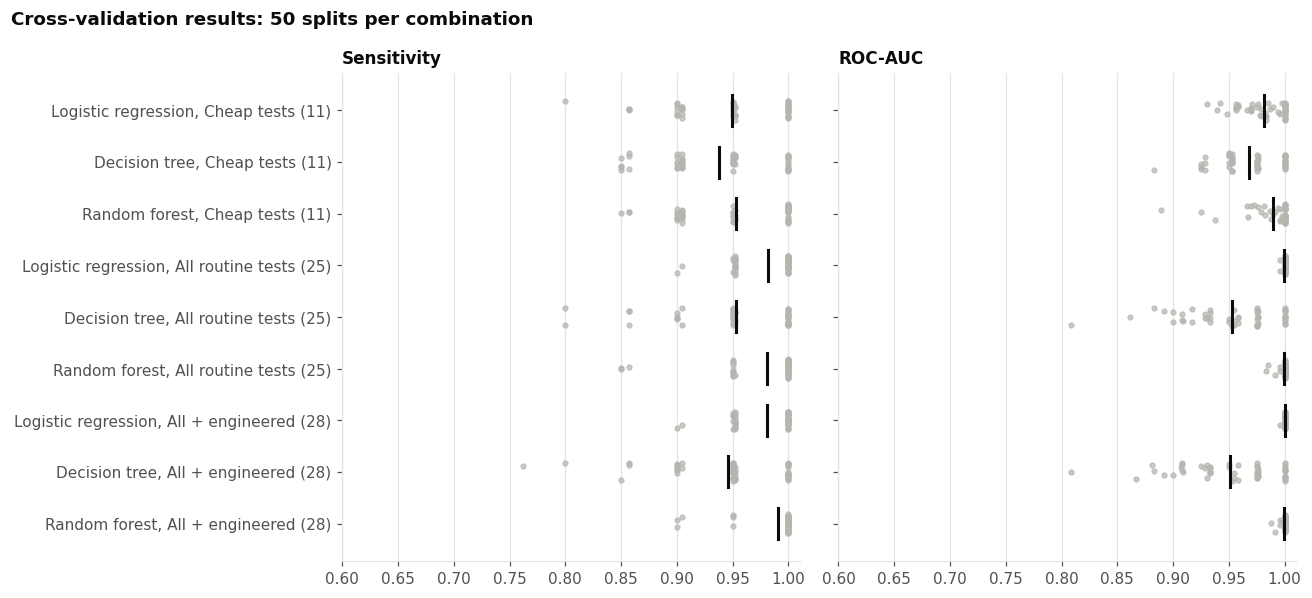

In [6]:
order = list(dict.fromkeys(fold_scores["Combination"]))[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
rng = np.random.default_rng(0)
for ax, metric in zip(axes, ["Sensitivity", "ROC-AUC"]):
    for i, combo in enumerate(order):
        vals = fold_scores.loc[fold_scores["Combination"] == combo, metric]
        ax.scatter(vals, i + rng.uniform(-0.18, 0.18, len(vals)), s=10, color="#b5b4ae", alpha=0.7)
        ax.plot([vals.mean()] * 2, [i - 0.3, i + 0.3], color=TEXT, linewidth=2)
    ax.set_title(metric)
    ax.set_xlim(0.6, 1.01)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(order)))
axes[0].set_yticklabels(order)
fig.suptitle("Cross-validation results: 50 splits per combination", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig("figures/pred_cv_spread.png")
plt.show()

## Step 4: Choose the final models
We keep **logistic regression** for both feature sets:
- its sensitivity is among the best (within 0.01 of the top), with the highest ROC-AUC and the smallest spread; sensitivity matters most because missing a CKD patient is the costly error;
- it is the easiest to explain to clinicians (each test pushes the risk up or down by a fixed amount);
- it gives probabilities that can be used as a risk score.

**Full model** = logistic regression on all 25 routine tests. **Cheap-test model** = logistic regression on the 11 cheap tests. Engineered features are not used in the final models: they only nudged the random forest (sensitivity 0.981 → 0.991, well within the spread) and did not change logistic regression, so the simpler 25-test set is kept.

In [7]:
FINAL = {
    "Full model": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), FEATURES),
    "Cheap-test model": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), CHEAP),
}
for name, (model, cols) in FINAL.items():
    model.fit(train[cols], y_train)
print("Both final models trained on all 160 training patients.")

Both final models trained on all 160 training patients.


## Step 5: One-time evaluation on the 40 test patients
This is the only time the test set is used. Expected:
- Full model: catches 26 of 26 CKD patients and wrongly flags 0 of 14 non-CKD patients (sensitivity 1.00, specificity 1.00).
- Cheap-test model: catches 25 of 26 CKD patients (sensitivity 0.96), wrongly flags 0 of 14 (specificity 1.00).

With only 40 test patients, one patient changes sensitivity by about 4 percentage points, so the cross-validation results in Step 2 are the more reliable estimate.

In [8]:
test_rows, probs = [], {}
for name, (model, cols) in FINAL.items():
    p = model.predict_proba(test[cols])[:, 1]
    pred = (p >= 0.5).astype(int)
    probs[name] = p
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    test_rows.append({"Model": name, "CKD caught": f"{tp} of {tp + fn}",
                      "False alarms": f"{fp} of {fp + tn}",
                      "Sensitivity": round(tp / (tp + fn), 3), "Specificity": round(tn / (tn + fp), 3),
                      "ROC-AUC": round(roc_auc_score(y_test, p), 3), "F1": round(f1_score(y_test, pred), 3)})
test_results = pd.DataFrame(test_rows).set_index("Model")
test_results

,CKD caught,False alarms,Sensitivity,Specificity,ROC-AUC,F1
Model,,,,,,
Full model,26 of 26,0 of 14,1.000,1.0,1.0,1.00
Cheap-test model,25 of 26,0 of 14,0.962,1.0,1.0,0.98


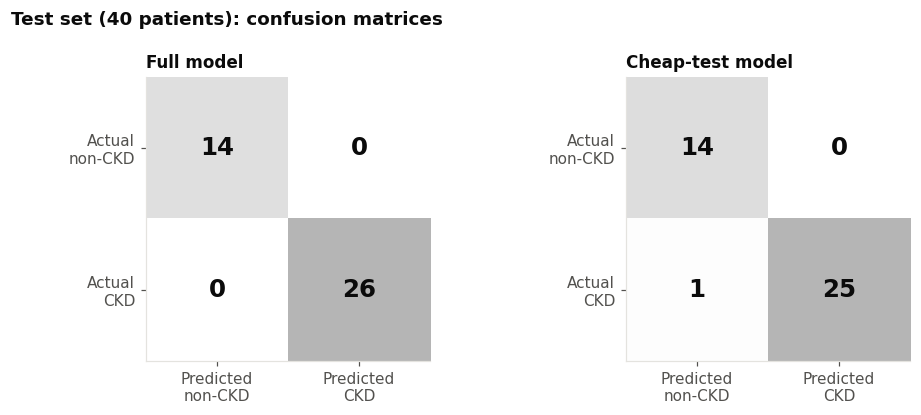

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, name in zip(axes, FINAL):
    cm = confusion_matrix(y_test, (probs[name] >= 0.5).astype(int))
    ax.imshow(cm, cmap="Greys", vmin=0, vmax=cm.max() * 2.5)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16, fontweight="bold")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicted\nnon-CKD", "Predicted\nCKD"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual\nnon-CKD", "Actual\nCKD"])
    ax.grid(False)
    ax.set_title(name)
fig.suptitle("Test set (40 patients): confusion matrices", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig("figures/pred_confusion.png")
plt.show()

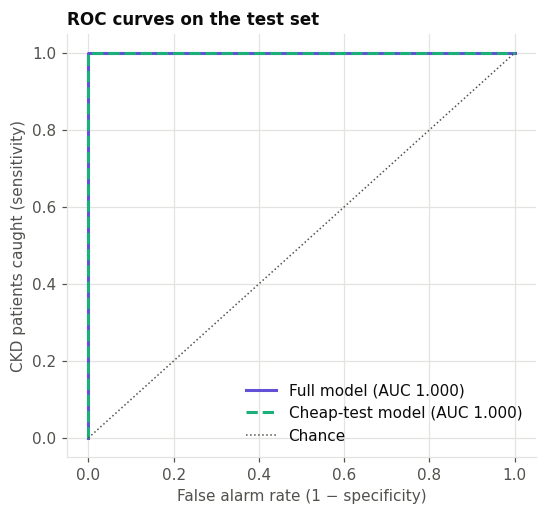

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for name in FINAL:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    ax.plot(fpr, tpr, MODEL_STYLES[name], color=MODEL_COLORS[name], linewidth=2,
            label=f"{name} (AUC {roc_auc_score(y_test, probs[name]):.3f})")
ax.plot([0, 1], [0, 1], ":", color=MUTED, linewidth=1, label="Chance")
ax.set_xlabel("False alarm rate (1 − specificity)")
ax.set_ylabel("CKD patients caught (sensitivity)")
ax.set_title("ROC curves on the test set")
ax.grid(axis="x")
ax.legend(loc="lower right")
fig.savefig("figures/pred_roc.png")
plt.show()

## Step 6: Can the risk score be trusted as a probability? (calibration)
If the model says "70% risk", about 70% of such patients should have CKD. We check this with cross-validated predictions on the training set (more patients than the test set). Points close to the dotted diagonal = well calibrated. The Brier score is the average squared error of the probabilities (0 = perfect).

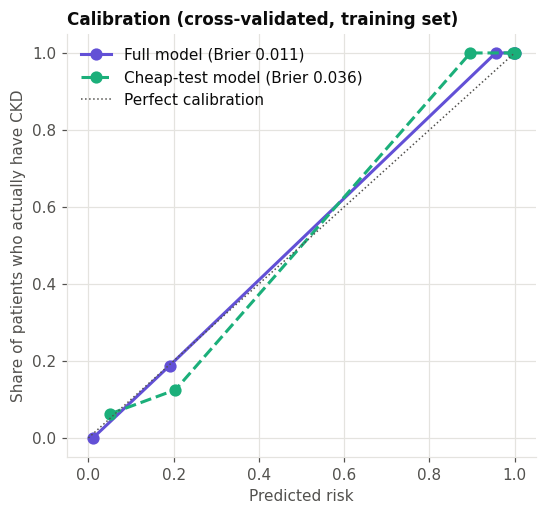

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 5))
cv5 = StratifiedKFold(5, shuffle=True, random_state=42)
for name, (model, cols) in FINAL.items():
    p_cv = cross_val_predict(model, train[cols], y_train, cv=cv5, method="predict_proba")[:, 1]
    frac, mean_p = calibration_curve(y_train, p_cv, n_bins=5, strategy="quantile")
    ax.plot(mean_p, frac, MODEL_STYLES[name], marker="o", markersize=7, color=MODEL_COLORS[name],
            linewidth=2, label=f"{name} (Brier {brier_score_loss(y_train, p_cv):.3f})")
ax.plot([0, 1], [0, 1], ":", color=MUTED, linewidth=1, label="Perfect calibration")
ax.set_xlabel("Predicted risk")
ax.set_ylabel("Share of patients who actually have CKD")
ax.set_title("Calibration (cross-validated, training set)")
ax.grid(axis="x")
ax.legend(loc="upper left")
fig.savefig("figures/pred_calibration.png")
plt.show()

Brier score about 0.01 (full model) and 0.04 (cheap-test model). Most probabilities are close to 0 or 1, because the groups separate so clearly in this dataset.

## Step 7: Which tests drive the risk score?
Logistic regression coefficients on standardised values: the bar length shows how strongly a test moves the risk, and the direction shows whether higher values raise (right) or lower (left) the risk. The top 12 tests of the full model are shown.



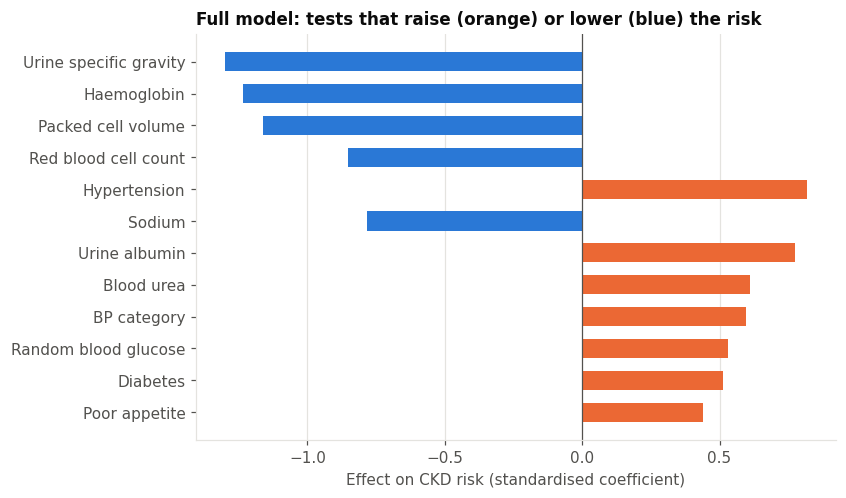

In [12]:
lr = FINAL["Full model"][0][-1]
coefs = pd.Series(lr.coef_[0], index=FEATURES)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index[:12])[::-1]
NAMES = {"hemo": "Haemoglobin", "sg": "Urine specific gravity", "al": "Urine albumin",
         "htn": "Hypertension", "dm": "Diabetes", "pcv": "Packed cell volume",
         "rbcc": "Red blood cell count", "sod": "Sodium", "bu": "Blood urea", "sc": "Serum creatinine",
         "bgr": "Random blood glucose", "su": "Urine sugar", "appet": "Poor appetite", "pe": "Pedal oedema",
         "ane": "Anaemia", "cad": "Coronary artery disease", "age": "Age", "bp": "Diastolic BP flag",
         "bp limit": "BP category", "pc": "Abnormal pus cells", "pcc": "Pus cell clumps",
         "rbc": "Abnormal red cells", "ba": "Bacteria", "pot": "Potassium", "wbcc": "White blood cell count"}
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.barh([NAMES[f] for f in top.index], top.values,
        color=["#eb6834" if v > 0 else "#2a78d6" for v in top.values], height=0.6)
ax.axvline(0, color=MUTED, linewidth=0.8)
ax.set_xlabel("Effect on CKD risk (standardised coefficient)")
ax.set_title("Full model: tests that raise (orange) or lower (blue) the risk")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
fig.savefig("figures/pred_drivers.png")
plt.show()

lower urine specific gravity, lower haemoglobin and lower packed cell volume are the strongest drivers; hypertension, higher albumin, higher urea, BP category, glucose and diabetes raise the risk.

## Step 8: Overfitting check (learning curve)
How do training and validation scores change as the model sees more patients? If the validation score is far below the training score, the model is overfitting. Close lines that level off = enough data for this model.



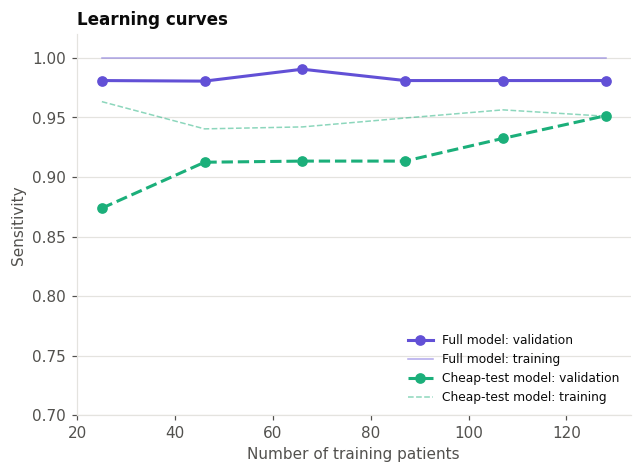

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name, (model, cols) in FINAL.items():
    sizes, tr_scores, va_scores = learning_curve(
        model, train[cols], y_train, cv=cv5, scoring="recall",
        train_sizes=np.linspace(0.2, 1.0, 6), random_state=42, shuffle=True)
    ax.plot(sizes, va_scores.mean(axis=1), MODEL_STYLES[name], marker="o", color=MODEL_COLORS[name],
            linewidth=2, label=f"{name}: validation")
    ax.plot(sizes, tr_scores.mean(axis=1), MODEL_STYLES[name], color=MODEL_COLORS[name],
            linewidth=1, alpha=0.5, label=f"{name}: training")
ax.set_xlabel("Number of training patients")
ax.set_ylabel("Sensitivity")
ax.set_ylim(0.7, 1.02)
ax.set_title("Learning curves")
ax.legend(loc="lower right", fontsize=8)
fig.savefig("figures/pred_learning_curve.png")
plt.show()

The full model is flat at about 0.98 from only 25 patients (the groups are easy to separate). The cheap-test model is still rising (0.87 → 0.95), so more patients would likely improve it.

## Step 9: Save the test-set risk scores
The prescriptive notebook rebuilds these models itself, but the scores are saved here as a record.

In [14]:
risks = test[["class"]].copy()
risks["risk_full_model"] = probs["Full model"].round(3)
risks["risk_cheap_test_model"] = probs["Cheap-test model"].round(3)
risks.to_csv("figures/pred_test_risks.csv")
cv_results.to_csv("figures/pred_cv_results.csv", index=False)
test_results.to_csv("figures/pred_test_results.csv")
risks.head()

,class,risk_full_model,risk_cheap_test_model
25,0,0.005,0.190
82,1,1.000,1.000
99,1,0.998,1.000
147,1,1.000,1.000
48,0,0.162,0.042


## Step 10: Findings (copy into the PB4 Trello card and the report)
1. **Routine tests detect current CKD almost perfectly in this dataset.** Logistic regression on all 25 routine tests: sensitivity 0.982 and ROC-AUC 1.000 in repeated cross-validation; on the 40 untouched test patients it caught 26 of 26 CKD patients with no false alarms. All models beat the always-CKD baseline (accuracy 0.64, specificity 0.00).
2. **Cheap tests alone get close.** Using only medical history, a urine dipstick, blood pressure and age, logistic regression reached sensitivity 0.949 and ROC-AUC 0.982 in cross-validation, and caught 25 of 26 CKD patients in the test set. This supports a low-cost first screening step where blood tests are not available for everyone (taken further in the prescriptive notebook).
3. **The risk score behaves like a probability.** Calibration is close to the diagonal (Brier score 0.011 full model, 0.036 cheap-test model), although most scores are near 0 or 1.
4. **Main drivers:** low urine specific gravity, low haemoglobin / packed cell volume (anaemia), hypertension and albumin in the urine.
5. **Overfitting check:** results are stable across 50 validation splits and the learning curve shows no gap between training and validation for the full model. Decision trees are the least stable model.
6. **Why so high, and what it means:** the non-CKD group has no comorbidities and no abnormal urine findings, so the two groups are unusually easy to separate. Results come from 200 patients at one hospital, with lab values given only as ranges; the model must be validated on a typical clinic population, ideally from another hospital, before any clinical use. The model detects current CKD and cannot predict progression.

## Step 11: Download all figures

In [15]:
import shutil
from google.colab import files

shutil.make_archive("predictive_figures", "zip", "figures")
files.download("predictive_figures.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>